In [65]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import Perceptron
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import confusion_matrix, recall_score, precision_score, accuracy_score
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_classification, make_biclusters, make_friedman1, make_circles, make_moons

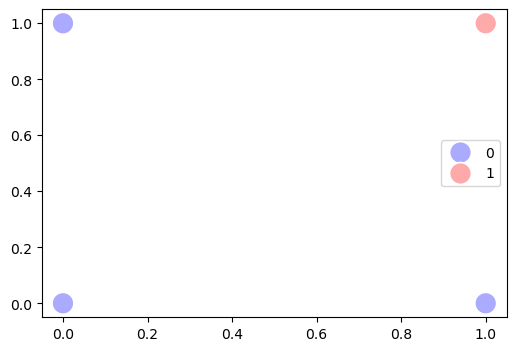

In [2]:
# Creating and gate
X = np.array([0, 0, 0, 1, 1, 0, 1, 1]).reshape(4, 2)
y = np.array([0, 0, 0, 1])

plt.figure(figsize=(6, 4))
sns.scatterplot(x=X[:,0], y=X[:, 1], hue=y.astype(str), s=250, marker='o', palette='bwr')
plt.show()


In [3]:
model = Perceptron(max_iter=50, eta0=0.5)
model.fit(X, y)

,penalty,None
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,50
,tol,0.001
,shuffle,True
,verbose,0
,eta0,0.5
,n_jobs,None
,random_state,0


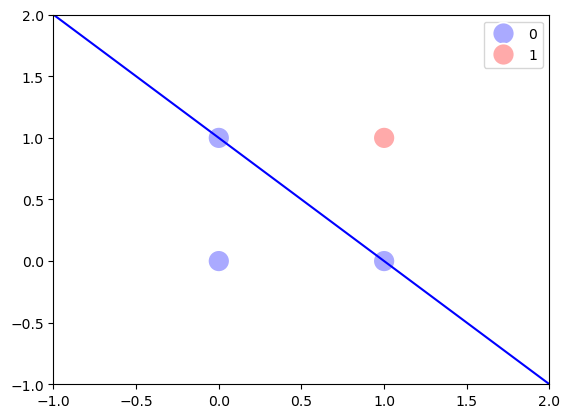

In [4]:
plt.figure()
sns.scatterplot(x=X[:,0], y=X[:, 1], hue=y.astype(str), s=250, marker='o', palette='bwr')
display = DecisionBoundaryDisplay.from_estimator(
    model, 
    X,
    response_method='decision_function', plot_method='contour',
    ax=plt.gca(),
    alpha=1,
    cmap='bwr',
    levels=[0]
)
plt.show()

In [5]:
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([0, 1, 1, 0])
def step(z):
    return 1 if z >= 0 else 0

w = np.random.randn(2)
b = 0.0
lr = 0.1

for epoch in range(1000):
    errors = 0
    for xi, target in zip(X, y):
        y_pred = step(w @ xi + b)
        err = target - y_pred
        w += lr * err * xi
        b += lr * err
        errors += abs(err)
    if errors == 0:
        print("Converged at epoch", epoch)
        break
else:
    print("Did not converge (expected for XOR)")

Did not converge (expected for XOR)


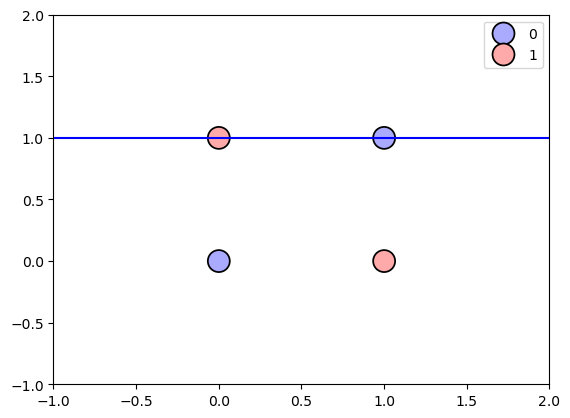

In [6]:
model = Perceptron(shuffle=True, random_state=26)
model.fit(X, y)
fig, ax = plt.subplots()
DecisionBoundaryDisplay.from_estimator(
    model, X,
    response_method='decision_function',
    plot_method='contour',
    cmap='bwr',
    ax=ax,
    levels=[0]
)
sns.scatterplot(x=X[:,0], y=X[:,1], hue=y, s=250, palette='bwr', ax=ax, edgecolor='k')
plt.show()

In [7]:
confusion_matrix(y, model.predict(X))

array([[2, 0],
       [2, 0]])

In [8]:
# This problem  can  be solved by the multilayer perceptron

In [32]:
model = MLPClassifier(
    solver='sgd', 
    hidden_layer_sizes=(2, ),
    activation='tanh',
    random_state=26,
    max_iter=1000,
    verbose=True,
    tol=1e-5, 
    momentum=0.7,
    learning_rate_init=0.2
)
model.fit(X, y)

Iteration 1, loss = 0.68530196
Iteration 2, loss = 0.68289993
Iteration 3, loss = 0.68039114
Iteration 4, loss = 0.67809407
Iteration 5, loss = 0.67608219
Iteration 6, loss = 0.67429278
Iteration 7, loss = 0.67261700
Iteration 8, loss = 0.67095476
Iteration 9, loss = 0.66923763
Iteration 10, loss = 0.66743066
Iteration 11, loss = 0.66552413
Iteration 12, loss = 0.66352294
Iteration 13, loss = 0.66143768
Iteration 14, loss = 0.65927887
Iteration 15, loss = 0.65705408
Iteration 16, loss = 0.65476723
Iteration 17, loss = 0.65241915
Iteration 18, loss = 0.65000858
Iteration 19, loss = 0.64753329
Iteration 20, loss = 0.64499095
Iteration 21, loss = 0.64237965
Iteration 22, loss = 0.63969812
Iteration 23, loss = 0.63694576
Iteration 24, loss = 0.63412252
Iteration 25, loss = 0.63122870
Iteration 26, loss = 0.62826484
Iteration 27, loss = 0.62523150
Iteration 28, loss = 0.62212914
Iteration 29, loss = 0.61895800
Iteration 30, loss = 0.61571790
Iteration 31, loss = 0.61240818
Iteration 32, los

,hidden_layer_sizes,"(2,)"
,activation,'tanh'
,solver,'sgd'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.2
,power_t,0.5
,max_iter,1000
,shuffle,True
,random_state,26


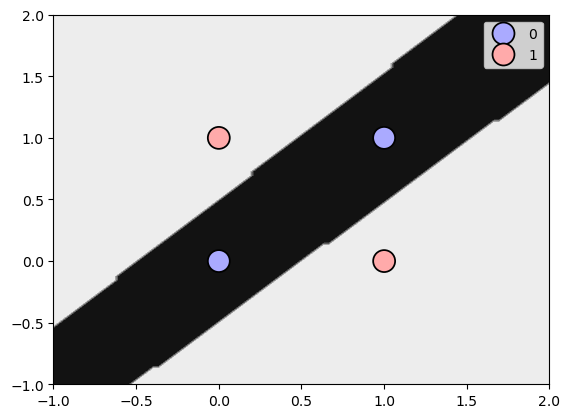

In [33]:

fig, ax = plt.subplots()
DecisionBoundaryDisplay.from_estimator(
    model, X,
    response_method='predict',
    plot_method='contourf',
    cmap='grey',
    ax=ax,
    # levels=[0]
)
sns.scatterplot(x=X[:,0], y=X[:,1], hue=y, s=250, palette='bwr', ax=ax, edgecolor='k')
plt.show()

In [23]:
confusion_matrix(y, model.predict(X))

array([[2, 0],
       [0, 2]])

C:\Users\hp\miniconda3\envs\pydata-book\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\hp\miniconda3\envs\pydata-book\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\hp\miniconda3\envs\pydata-book\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


[array([[-7.20908519, -4.58800875, -1.1310321 ,  0.94049938,  1.50883281],
       [-7.13573674, -4.69500082, -1.87222842,  1.05201179,  0.73081598]]), array([[-13.52284667],
       [  9.08148037],
       [  2.41779955],
       [ -3.23635651],
       [ -3.35552826]])] [array([ 3.14158449,  7.05730799,  2.1698049 , -1.21665223, -1.36455667]), array([-1.7922222])]


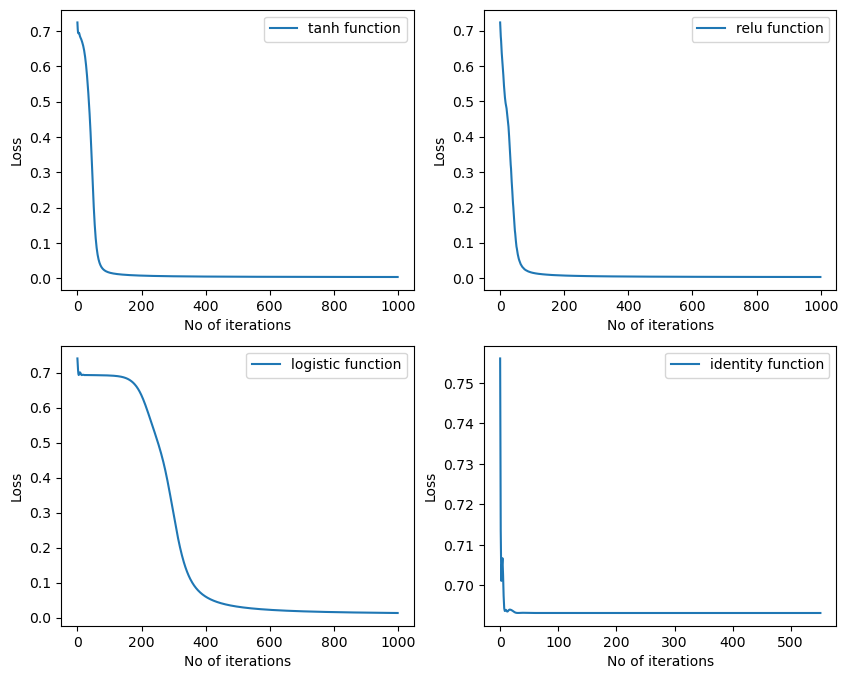

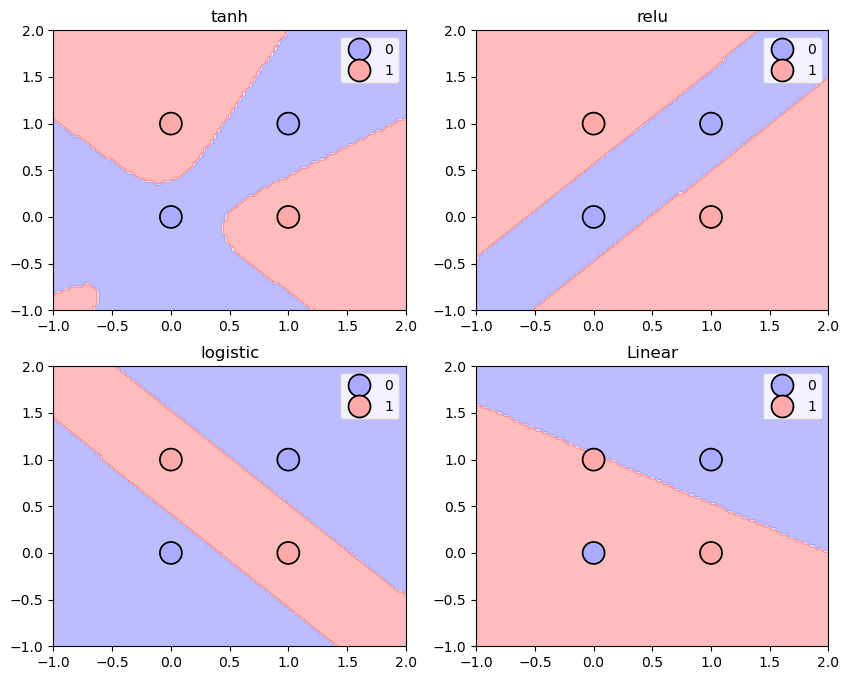

In [64]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8), sharey=False)
fig, ax2 = plt.subplots(2, 2, figsize=(10, 8), sharey=False)
ax2 = ax2.flatten()
ax = ax.flatten()
for i, activation in zip(range(4), ['tanh', 'relu', 'logistic', 'identity']):
    model = MLPClassifier(
    solver='sgd', 
    hidden_layer_sizes=(5, ),
    activation=activation,
    random_state=26,
    max_iter=1000,
    verbose=False,
    tol=1e-6, 
    momentum=0.9,
    n_iter_no_change=500,
    learning_rate_init=0.2
    )
    model.fit(X, y)
    
    ax[i].plot(model.loss_curve_, label=f'{activation} function')
    ax[i].legend()
    ax[i].set_xlabel('No of iterations')
    ax[i].set_ylabel('Loss')

    display = DecisionBoundaryDisplay.from_estimator(
        model, 
        X,
        response_method='predict', plot_method='contourf',
        alpha=0.3,
        cmap='bwr',
        ax=ax2[i]
    )
    sns.scatterplot(x=X[:,0], y=X[:, 1], hue=y.astype(str), s=250, marker='o', palette='bwr', ax=ax2[i], edgecolor='k')
    ax2[i].set_title(f'{activation}')

    if activation=='identity':
        ax2[i].set_title('Linear')
    if activation=='logistic':
        print(model.coefs_, model.intercepts_)
plt.show()
    
    
    

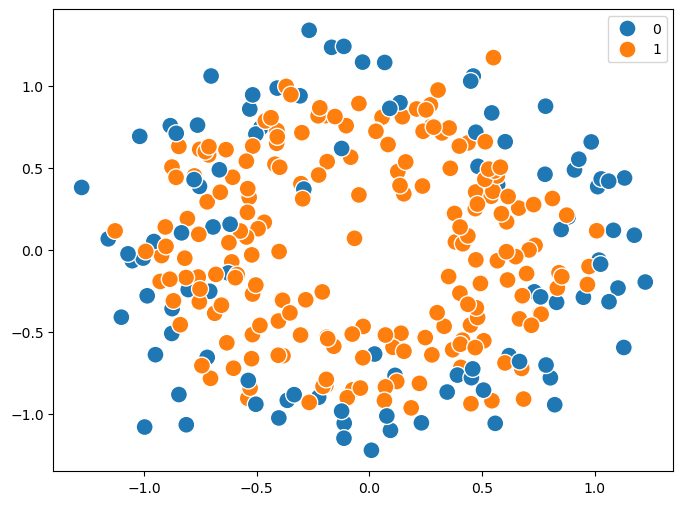

In [169]:
X, y= make_circles(factor=0.7, noise=0.2, n_samples=(100, 200))
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, s=150)
plt.show()

In [188]:
model = MLPClassifier(
    hidden_layer_sizes=(32, 16, 8), 
    activation='relu', 
    solver='adam', 
    learning_rate_init=1e-2,
    beta_1=0.9,
    beta_2=0.9,
    max_iter=10000,
    tol=1e-5,
    n_iter_no_change=200,
    verbose=True, 
    batch_size=150
)
model.fit(X, y)

Iteration 1, loss = 0.65279422
Iteration 2, loss = 0.63759616
Iteration 3, loss = 0.63451246
Iteration 4, loss = 0.62981130
Iteration 5, loss = 0.62310319
Iteration 6, loss = 0.61750828
Iteration 7, loss = 0.61338055
Iteration 8, loss = 0.60832113
Iteration 9, loss = 0.60180086
Iteration 10, loss = 0.59559112
Iteration 11, loss = 0.58825028
Iteration 12, loss = 0.58140899
Iteration 13, loss = 0.57221656
Iteration 14, loss = 0.56372532
Iteration 15, loss = 0.55583271
Iteration 16, loss = 0.54566069
Iteration 17, loss = 0.53346424
Iteration 18, loss = 0.52283879
Iteration 19, loss = 0.51442031
Iteration 20, loss = 0.50240210
Iteration 21, loss = 0.49250253
Iteration 22, loss = 0.48192739
Iteration 23, loss = 0.47123044
Iteration 24, loss = 0.46554198
Iteration 25, loss = 0.45333758
Iteration 26, loss = 0.44979392
Iteration 27, loss = 0.44150534
Iteration 28, loss = 0.44192681
Iteration 29, loss = 0.43223097
Iteration 30, loss = 0.43810974
Iteration 31, loss = 0.43243348
Iteration 32, los

,hidden_layer_sizes,"(32, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,150
,learning_rate,'constant'
,learning_rate_init,0.01
,power_t,0.5
,max_iter,10000
,shuffle,True
,random_state,None


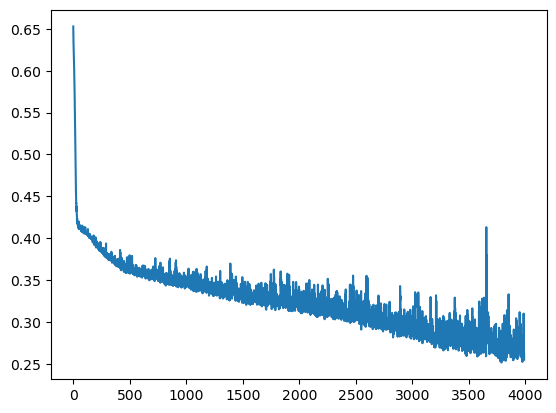

In [189]:
plt.figure()
plt.plot(model.loss_curve_)
plt.show()

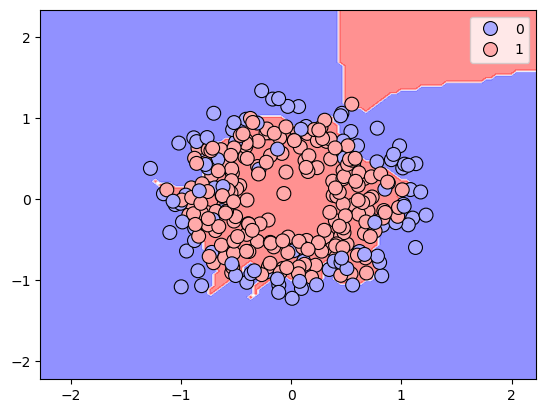

In [190]:

fig, ax = plt.subplots()
DecisionBoundaryDisplay.from_estimator(
    model, X,
    response_method='predict',
    plot_method='contourf',
    cmap='bwr', alpha=0.5,
    ax=ax
)
sns.scatterplot(x=X[:,0], y=X[:,1], hue=y, s=100, palette='bwr', ax=ax, edgecolor='k')
plt.show()